In [1]:
import os
print(os.listdir("../data"))

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [2]:
%pip install duckdb

   ---------------------------------------- 0.0/15.4 MB ? eta -:--:--
   --- ------------------------------------ 1.3/15.4 MB 7.2 MB/s eta 0:00:02
   -------- ------------------------------- 3.1/15.4 MB 7.7 MB/s eta 0:00:02
   ----------- ---------------------------- 4.5/15.4 MB 7.5 MB/s eta 0:00:02
   ---------------- ----------------------- 6.3/15.4 MB 7.9 MB/s eta 0:00:02
   --------------------- ------------------ 8.1/15.4 MB 7.8 MB/s eta 0:00:01
   ------------------------ --------------- 9.4/15.4 MB 7.7 MB/s eta 0:00:01
   ---------------------------- ----------- 11.0/15.4 MB 7.6 MB/s eta 0:00:01
   --------------------------------- ------ 12.8/15.4 MB 7.7 MB/s eta 0:00:01
   -------------------------------------- - 14.7/15.4 MB 8.0 MB/s eta 0:00:01
   ---------------------------------------- 15.4/15.4 MB 7.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [1]:
import duckdb
con = duckdb.connect("../olist.duckdb")

files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

for table, f in files.items():
    con.execute(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM read_csv_auto('../data/{f}')")
    print(table, con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0])

customers 99441
orders 99441
order_items 112650
payments 103886
reviews 99224
products 32951
sellers 3095
category_translation 71


In [2]:
import duckdb
con = duckdb.connect("../olist.duckdb")

In [3]:
con.execute("""
SELECT MIN(order_purchase_timestamp) AS first_order,
       MAX(order_purchase_timestamp) AS last_order
FROM orders
""").df()

,first_order,last_order
0,2016-09-04 21:15:19,2018-10-17 17:30:18


In [4]:
con.execute("""
SELECT order_status,
       COUNT(*) AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM orders
GROUP BY order_status
ORDER BY orders DESC
""").df()

,order_status,orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [5]:
con.execute("""
SELECT date_trunc('month', order_purchase_timestamp) AS month,
       COUNT(*) AS orders
FROM orders
GROUP BY month
ORDER BY month
""").df()

,month,orders
0,2016-09-01,4
1,2016-10-01,324
2,2016-12-01,1
3,2017-01-01,800
4,2017-02-01,1780
5,2017-03-01,2682
6,2017-04-01,2404
7,2017-05-01,3700
8,2017-06-01,3245
9,2017-07-01,4026


In [6]:
con.execute("""
SELECT
  (SELECT COUNT(*) FROM orders) AS orders,
  (SELECT COUNT(DISTINCT order_id) FROM order_items) AS orders_with_items,
  (SELECT COUNT(DISTINCT order_id) FROM payments) AS orders_with_payments,
  (SELECT COUNT(*) FROM order_items) AS item_rows,
  (SELECT COUNT(*) FROM payments) AS payment_rows
""").df()

,orders,orders_with_items,orders_with_payments,item_rows,payment_rows
0,99441,98666,99440,112650,103886


In [7]:
monthly = con.execute("""
WITH order_revenue AS (
    SELECT o.order_id,
           date_trunc('month', o.order_purchase_timestamp) AS month,
           SUM(oi.price) AS revenue
    FROM orders o
    JOIN order_items oi ON oi.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY o.order_id, month
)
SELECT month,
       COUNT(*) AS orders,
       ROUND(SUM(revenue), 2) AS revenue,
       ROUND(SUM(revenue) / COUNT(*), 2) AS aov,
       ROUND(100.0 * (SUM(revenue) - LAG(SUM(revenue)) OVER (ORDER BY month))
             / LAG(SUM(revenue)) OVER (ORDER BY month), 1) AS revenue_mom_pct
FROM order_revenue
GROUP BY month
ORDER BY month
""").df()
monthly

,month,orders,revenue,aov,revenue_mom_pct
0,2017-01-01,750,111798.36,149.06,NaN
1,2017-02-01,1653,234223.40,141.70,109.5
2,2017-03-01,2546,359198.85,141.08,53.4
3,2017-04-01,2303,340669.68,147.92,-5.2
4,2017-05-01,3546,489338.25,138.00,43.6
5,2017-06-01,3135,421923.37,134.58,-13.8
6,2017-07-01,3872,481604.52,124.38,14.1
7,2017-08-01,4193,554699.70,132.29,15.2
8,2017-09-01,4150,607399.67,146.36,9.5
9,2017-10-01,4478,648247.65,144.76,6.7


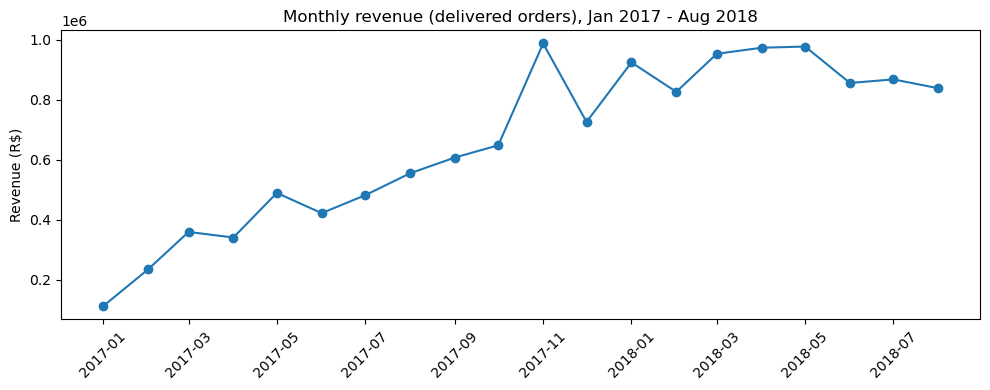

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(monthly["month"], monthly["revenue"], marker="o")
plt.title("Monthly revenue (delivered orders), Jan 2017 - Aug 2018")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
monthly.to_csv("../dashboard/monthly_kpis.csv", index=False)

In [10]:
con.execute("""
SELECT o.order_status, COUNT(*) AS orders_without_items
FROM orders o
LEFT JOIN order_items oi ON oi.order_id = o.order_id
WHERE oi.order_id IS NULL
GROUP BY o.order_status
ORDER BY 2 DESC
""").df()

,order_status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


In [11]:
print(monthly["revenue"].sum(), monthly["orders"].sum())

13181027.129999999 96211


In [12]:
con.execute("""
SELECT CAST(order_purchase_timestamp AS DATE) AS day, COUNT(*) AS orders
FROM orders
WHERE order_status = 'delivered'
  AND order_purchase_timestamp >= '2017-11-15'
  AND order_purchase_timestamp <  '2017-12-01'
GROUP BY day ORDER BY day
""").df()

,day,orders
0,2017-11-15,176
1,2017-11-16,219
2,2017-11-17,185
3,2017-11-18,141
4,2017-11-19,157
5,2017-11-20,219
6,2017-11-21,222
7,2017-11-22,190
8,2017-11-23,268
9,2017-11-24,1147


In [13]:
cat = con.execute("""
WITH item_rev AS (
    SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
           EXTRACT(year FROM o.order_purchase_timestamp) AS yr,
           oi.price AS revenue
    FROM orders o
    JOIN order_items oi ON oi.order_id = o.order_id
    JOIN products p ON p.product_id = oi.product_id
    LEFT JOIN category_translation t ON t.product_category_name = p.product_category_name
    WHERE o.order_status = 'delivered'
      AND EXTRACT(month FROM o.order_purchase_timestamp) BETWEEN 1 AND 8
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
)
SELECT category,
       ROUND(SUM(CASE WHEN yr = 2017 THEN revenue END), 0) AS rev_2017,
       ROUND(SUM(CASE WHEN yr = 2018 THEN revenue END), 0) AS rev_2018,
       ROUND(SUM(revenue), 0) AS total_rev,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS share_pct,
       ROUND(100.0 * (SUM(CASE WHEN yr = 2018 THEN revenue END)
                    - SUM(CASE WHEN yr = 2017 THEN revenue END))
             / NULLIF(SUM(CASE WHEN yr = 2017 THEN revenue END), 0), 1) AS yoy_pct
FROM item_rev
GROUP BY category
ORDER BY total_rev DESC
LIMIT 15
""").df()
cat

,category,rev_2017,rev_2018,total_rev,share_pct,yoy_pct
0,health_beauty,243522.0,755725.0,999246.0,9.8,210.3
1,watches_gifts,201138.0,687855.0,888993.0,8.7,242.0
2,bed_bath_table,254445.0,532359.0,786804.0,7.7,109.2
3,sports_leisure,216724.0,517166.0,733891.0,7.2,138.6
4,computers_accessories,214631.0,496269.0,710901.0,7.0,131.2
5,furniture_decor,170859.0,381650.0,552508.0,5.4,123.4
6,housewares,127535.0,391823.0,519358.0,5.1,207.2
7,auto,125247.0,343288.0,468536.0,4.6,174.1
8,cool_stuff,206306.0,227744.0,434050.0,4.3,10.4
9,garden_tools,138051.0,212186.0,350237.0,3.4,53.7


In [14]:
cat.to_csv("../dashboard/category_performance.csv", index=False)

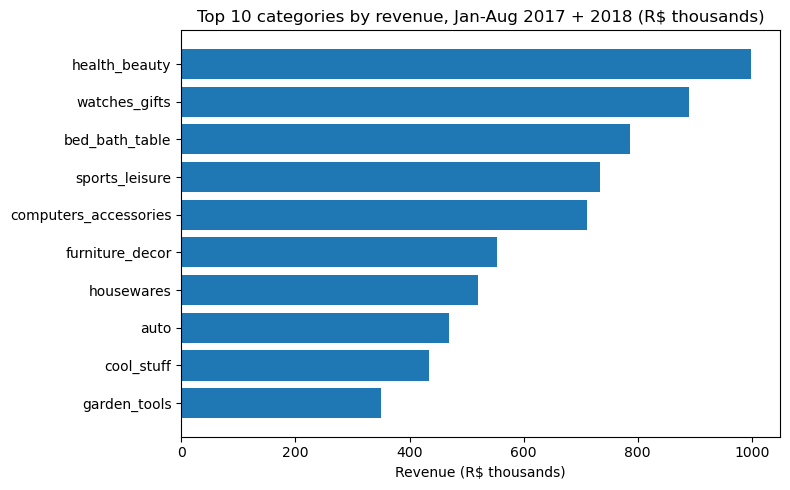

In [15]:
import matplotlib.pyplot as plt
top = cat.head(10).sort_values("total_rev")
plt.figure(figsize=(8, 5))
plt.barh(top["category"], top["total_rev"] / 1000)
plt.title("Top 10 categories by revenue, Jan-Aug 2017 + 2018 (R$ thousands)")
plt.xlabel("Revenue (R$ thousands)")
plt.tight_layout()
plt.show()

In [16]:
rep = con.execute("""
WITH cust_orders AS (
    SELECT c.customer_unique_id,
           COUNT(DISTINCT o.order_id) AS n_orders,
           SUM(oi.price) AS revenue
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    JOIN order_items oi ON oi.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY c.customer_unique_id
)
SELECT CASE WHEN n_orders = 1 THEN 'one-time' ELSE 'repeat (2+)' END AS segment,
       COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_customers,
       ROUND(SUM(revenue), 0) AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS pct_revenue,
       ROUND(AVG(revenue), 2) AS avg_revenue_per_customer
FROM cust_orders
GROUP BY segment
ORDER BY customers DESC
""").df()
rep

,segment,customers,pct_customers,revenue,pct_revenue,avg_revenue_per_customer
0,one-time,90315,97.0,12455672.0,94.5,137.91
1,repeat (2+),2789,3.0,725355.0,5.5,260.08


In [17]:
d = con.execute("""
WITH rev AS (
    SELECT order_id, AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
),
delivered AS (
    SELECT o.order_id,
           date_diff('day',
                     CAST(o.order_estimated_delivery_date AS DATE),
                     CAST(o.order_delivered_customer_date AS DATE)) AS days_late
    FROM orders o
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
)
SELECT CASE
         WHEN days_late <= 0 THEN '1. On time or early'
         WHEN days_late <= 3 THEN '2. Late 1-3 days'
         WHEN days_late <= 7 THEN '3. Late 4-7 days'
         ELSE '4. Late 8+ days'
       END AS delivery_bucket,
       COUNT(*) AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_orders,
       ROUND(AVG(r.review_score), 2) AS avg_review,
       ROUND(100.0 * AVG(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END), 1) AS pct_low_reviews
FROM delivered d
JOIN rev r ON r.order_id = d.order_id
GROUP BY delivery_bucket
ORDER BY delivery_bucket
""").df()
d

,delivery_bucket,orders,pct_orders,avg_review,pct_low_reviews
0,1. On time or early,89182,93.3,4.29,9.2
1,2. Late 1-3 days,1851,1.9,3.29,32.2
2,3. Late 4-7 days,1748,1.8,2.11,67.6
3,4. Late 8+ days,2779,2.9,1.70,79.2


In [18]:
state = con.execute("""
SELECT c.customer_state,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(CASE WHEN CAST(o.order_delivered_customer_date AS DATE)
                                 > CAST(o.order_estimated_delivery_date AS DATE)
                              THEN 1 ELSE 0 END), 1) AS pct_late
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY c.customer_state
HAVING COUNT(*) >= 500
ORDER BY pct_late DESC
""").df()
state

,customer_state,orders,pct_late
0,MA,713,17.5
1,CE,1273,13.8
2,BA,3253,12.2
3,RJ,12310,12.1
4,PA,942,11.3
5,ES,1992,10.7
6,PB,516,10.5
7,MS,701,9.7
8,PE,1587,9.6
9,SC,3537,8.2


In [19]:
d.to_csv("../dashboard/delivery_vs_reviews.csv", index=False)
rep.to_csv("../dashboard/repeat_customers.csv", index=False)
state.to_csv("../dashboard/late_by_state.csv", index=False)  